# Credit Card Fraud Detection

**Goal:** detect fraudulent credit card transactions in a highly imbalanced dataset.

**Approach**
- Supervised learning, because every transaction has a fraud / not-fraud label.
- Exploratory data analysis and class imbalance visualization.
- Sampling approaches: SMOTE, and SMOTE combined with random undersampling.
- Models: XGBoost and Random Forest.
- Metrics: precision, recall, F1, ROC-AUC and PR-AUC (accuracy is misleading on imbalanced data).
- Decision threshold chosen using a business cost analysis.

**Dataset:** 284,807 European card transactions. `V1` to `V28` are anonymized PCA features, `Time` and `Amount` are raw, and `Class` is the target (`1` = fraud).

## 0. Setup

In [36]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier

Helper functions that save graphs to `outputs/graphs/` and models to `outputs/models/`. The folders are created automatically.

In [37]:
OUTPUT_DIR = "outputs"
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
GRAPHS_DIR = os.path.join(OUTPUT_DIR, "graphs")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)


def save_plot(filename, dpi=150):
    path = os.path.join(GRAPHS_DIR, filename)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Graph saved: {path}")


def save_artifacts(model, scaler, threshold, feature_columns, extra_models=None):
    joblib.dump(model, os.path.join(MODELS_DIR, "xgboost_fraud_model.pkl"))
    joblib.dump(scaler, os.path.join(MODELS_DIR, "scaler.pkl"))

    config = {"threshold": threshold, "feature_columns": list(feature_columns)}
    with open(os.path.join(MODELS_DIR, "config.json"), "w") as f:
        json.dump(config, f, indent=2)

    if extra_models:
        for name, m in extra_models.items():
            joblib.dump(m, os.path.join(MODELS_DIR, f"{name}.pkl"))

    print(f"Models saved in: {MODELS_DIR}")

## 1. Load and inspect the data

In [38]:
data_frame = pd.read_csv("Data/creditcard.csv")

In [39]:
print(data_frame.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [40]:
print(data_frame.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


### Data quality checks
Missing values and duplicate rows are checked, and duplicates are removed so the same transaction cannot appear in both the train and test sets.

In [41]:
print(data_frame.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [42]:
print(data_frame.duplicated().sum())

1081


In [43]:
data_frame = data_frame.drop_duplicates()
print(data_frame.duplicated().sum())

0


In [44]:
print(data_frame.shape)

(283726, 31)


There are no missing values. 1,081 duplicate rows were found and removed, leaving 283,726 transactions.

## 2. Class imbalance

In [45]:
print(data_frame["Class"].value_counts())
print(data_frame["Class"].value_counts(normalize=True) * 100)

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


Graph saved: outputs\graphs\01_class_distribution.png


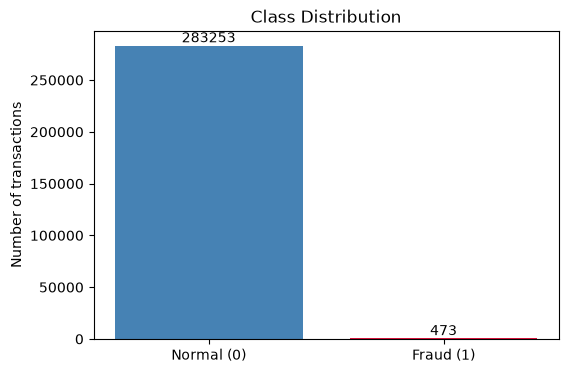

In [46]:
counts = data_frame["Class"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(["Normal (0)", "Fraud (1)"], counts.values, color=["steelblue", "crimson"])
plt.title("Class Distribution")
plt.ylabel("Number of transactions")
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
save_plot("01_class_distribution.png")
plt.show()

The dataset is highly imbalanced: only 473 of 283,726 transactions (0.17%) are fraud, roughly 1 fraud for every 600 normal transactions.

A model that predicts "normal" for everything would reach 99.83% accuracy while catching no fraud at all. Accuracy is therefore not used. Precision, recall and PR-AUC are used instead.

## 3. Exploratory data analysis

### Transaction amount by class

Graph saved: outputs\graphs\02_amount_distribution.png


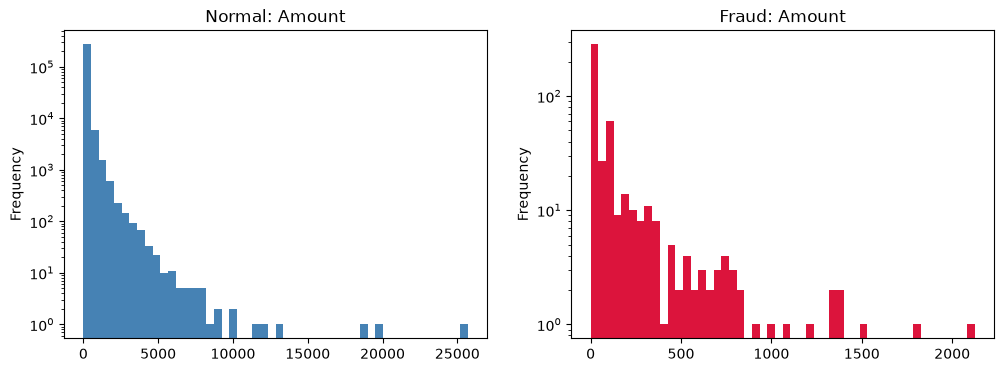

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data_frame[data_frame["Class"] == 0]["Amount"].plot(kind="hist", bins=50, ax=axes[0], color="steelblue", log=True)
axes[0].set_title("Normal: Amount")

data_frame[data_frame["Class"] == 1]["Amount"].plot(kind="hist", bins=50, ax=axes[1], color="crimson", log=True)
axes[1].set_title("Fraud: Amount")

save_plot("02_amount_distribution.png")
plt.show()

In [48]:
print(data_frame.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


Most transactions in both classes are small. Normal transactions go up to about 25,000, while the largest fraud is about 2,100, so fraud is concentrated in small amounts. `Amount` is strongly right-skewed with outliers, so `RobustScaler` is used later because it is less sensitive to outliers than standard scaling.

### Time distribution by class

Graph saved: outputs\graphs\03_time_distribution.png


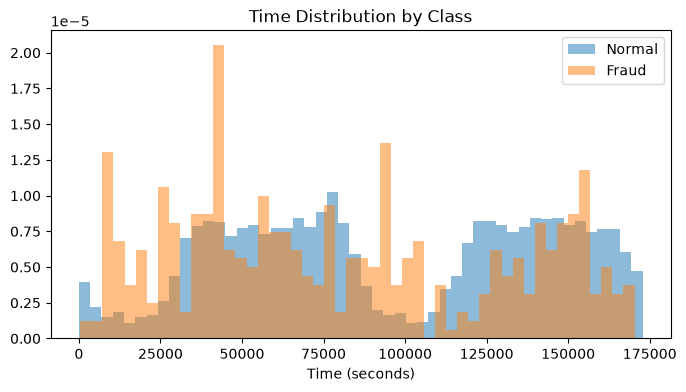

In [49]:
plt.figure(figsize=(8, 4))
plt.hist(data_frame[data_frame["Class"] == 0]["Time"], bins=50, alpha=0.5, label="Normal", density=True)
plt.hist(data_frame[data_frame["Class"] == 1]["Time"], bins=50, alpha=0.5, label="Fraud", density=True)
plt.legend()
plt.title("Time Distribution by Class")
plt.xlabel("Time (seconds)")
save_plot("03_time_distribution.png")
plt.show()

Normal transactions follow a day / night cycle. Fraud is more uneven, with spikes around 10k, 40k and 90k seconds, and it still occurs when normal activity is low. With only 473 fraud cases some of these spikes are probably noise, so `Time` alone is not a strong feature.

### Correlation of each feature with the target

Graph saved: outputs\graphs\04_correlation.png


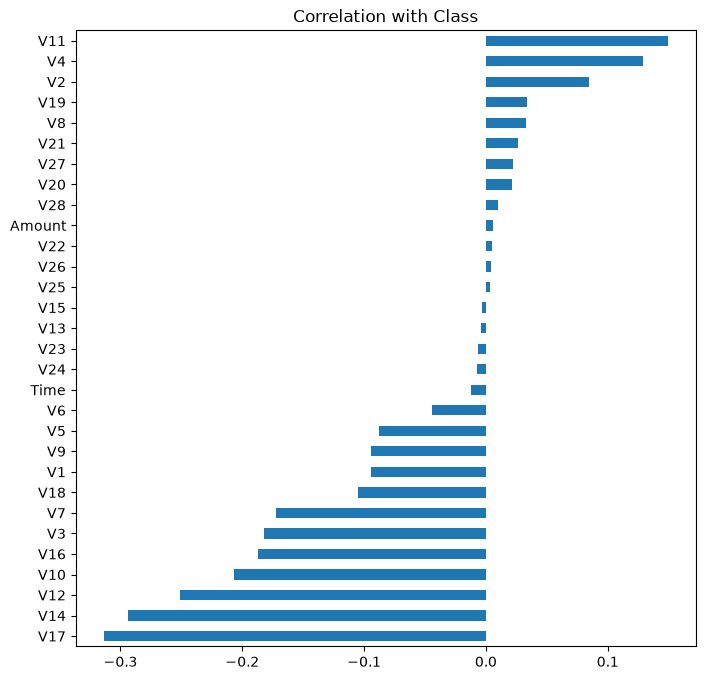

In [50]:
corr = data_frame.corr()["Class"].drop("Class").sort_values()
plt.figure(figsize=(8, 8))
corr.plot(kind="barh")
plt.title("Correlation with Class")
save_plot("04_correlation.png")
plt.show()

`V17`, `V14`, `V12` and `V10` are the most negatively correlated with fraud (`V17` is about -0.31), while `V11` and `V4` are the most positively correlated. `Time` and `Amount` show almost no linear correlation.

Correlation only captures linear relationships. Tree-based models can use non-linear patterns, so no feature is dropped based on correlation alone.

## 4. Train / test split and scaling
The split is **stratified** so both sets keep the same fraud ratio. The split is done **before** scaling and sampling, and the scaler is fitted on the training set only, to avoid data leakage. Only `Time` and `Amount` are scaled because `V1` to `V28` are already PCA outputs.

In [51]:
X = data_frame.drop("Class", axis=1)
y = data_frame["Class"]

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [53]:
scaler = RobustScaler()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

(226980, 30) (56746, 30)
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


Train has 226,980 rows and test has 56,746 rows. Fraud is 0.167% in both, so the stratified split worked. The test set has about 95 fraud cases, so metrics on it can move noticeably with just one or two cases.

## 5. Handling class imbalance
Sampling is applied to the **training set only**. The test set is never resampled, so it still reflects real-world data.

1. **SMOTE:** creates synthetic fraud samples until both classes are equal.
2. **SMOTE + undersampling:** SMOTE raises fraud to 10% of normal, then random undersampling reduces normal so fraud is 50% of normal (a 2:1 ratio).
3. **Original data with class weights:** no resampling, the model is told to penalize fraud mistakes more (`scale_pos_weight` for XGBoost, `class_weight` for Random Forest).

In [54]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64


In [55]:
combined = Pipeline([
    ("over", SMOTE(sampling_strategy=0.1, random_state=42)),
    ("under", RandomUnderSampler(sampling_strategy=0.5, random_state=42)),
])
X_train_comb, y_train_comb = combined.fit_resample(X_train, y_train)

print("After SMOTE + Undersampling:")
print(y_train_comb.value_counts())

After SMOTE + Undersampling:
Class
0    45320
1    22660
Name: count, dtype: int64


SMOTE turns 378 real fraud cases into about 226,000 samples, so most of the fraud in the SMOTE training set is synthetic. For this reason all results are judged on the untouched test set, never on training scores.

## 6. Model training and comparison
XGBoost and Random Forest are trained on each of the three training sets (6 models in total). All are evaluated on the same untouched test set with the default threshold of 0.5.

Class weights are used only on the original data. The SMOTE datasets are already balanced, so adding weights there would correct the imbalance twice.

In [56]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

datasets = {
    "Original": (X_train, y_train),
    "SMOTE": (X_train_smote, y_train_smote),
    "SMOTE+Under": (X_train_comb, y_train_comb),
}

results = []
trained_models = {}

for data_name, (Xtr, ytr) in datasets.items():
    spw = ratio if data_name == "Original" else 1
    cw = "balanced" if data_name == "Original" else None

    models = {
        "XGBoost": XGBClassifier(
            n_estimators=200, max_depth=5, learning_rate=0.1,
            scale_pos_weight=spw, eval_metric="aucpr",
            random_state=42, n_jobs=-1
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=100, class_weight=cw,
            random_state=42, n_jobs=-1
        ),
    }

    for model_name, model in models.items():
        model.fit(Xtr, ytr)
        proba = model.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)

        results.append({
            "Sampling": data_name,
            "Model": model_name,
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "PR-AUC": average_precision_score(y_test, proba),
        })
        trained_models[(data_name, model_name)] = model
        print(f"Done: {data_name} + {model_name}")

results_df = pd.DataFrame(results).round(4)
print(results_df.sort_values("PR-AUC", ascending=False).to_string(index=False))

results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)

Done: Original + XGBoost
Done: Original + RandomForest
Done: SMOTE + XGBoost
Done: SMOTE + RandomForest
Done: SMOTE+Under + XGBoost
Done: SMOTE+Under + RandomForest
   Sampling        Model  Precision  Recall     F1  ROC-AUC  PR-AUC
   Original      XGBoost     0.8824  0.7895 0.8333   0.9692  0.8204
      SMOTE      XGBoost     0.5532  0.8211 0.6610   0.9653  0.8142
      SMOTE RandomForest     0.9136  0.7789 0.8409   0.9590  0.8073
SMOTE+Under      XGBoost     0.5390  0.8000 0.6441   0.9700  0.8063
SMOTE+Under RandomForest     0.7857  0.8105 0.7979   0.9710  0.8020
   Original RandomForest     0.9710  0.7053 0.8171   0.9246  0.7960


### Results at threshold 0.5

| Sampling | Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Original | XGBoost | 0.8824 | 0.7895 | 0.8333 | 0.9692 | 0.8204 |
| SMOTE | XGBoost | 0.5532 | 0.8211 | 0.6610 | 0.9653 | 0.8142 |
| SMOTE | RandomForest | 0.9136 | 0.7789 | 0.8409 | 0.9590 | 0.8073 |
| SMOTE+Under | XGBoost | 0.5390 | 0.8000 | 0.6441 | 0.9700 | 0.8063 |
| SMOTE+Under | RandomForest | 0.7857 | 0.8105 | 0.7979 | 0.9710 | 0.8020 |
| Original | RandomForest | 0.9710 | 0.7053 | 0.8171 | 0.9246 | 0.7960 |

- PR-AUC values are close (0.796 to 0.820). With only about 95 fraud cases in the test set, this gap is small enough to be partly noise, so there is no clear winner.
- SMOTE made XGBoost catch slightly more fraud (recall 0.79 to 0.82) but its precision dropped sharply (0.88 to 0.55), meaning many more false alarms.
- **Original + XGBoost** has the best PR-AUC and a good balance of precision (0.88) and recall (0.79) without any resampling, so it is chosen as the final model.
- Random Forest on the original data has the highest precision (0.97) but the lowest recall (0.71), so it misses the most fraud.
- ROC-AUC looks high for every model and is optimistic on imbalanced data, so PR-AUC is used as the main guide.

## 7. Precision vs recall and threshold selection
The default threshold of 0.5 is not necessarily the best choice. Lowering the threshold catches more fraud (higher recall) but flags more legitimate transactions (lower precision). The curves below show this trade-off for the final model.

In [57]:
final_model = trained_models[("Original", "XGBoost")]
proba = final_model.predict_proba(X_test)[:, 1]

Graph saved: outputs\graphs\05_pr_curve.png


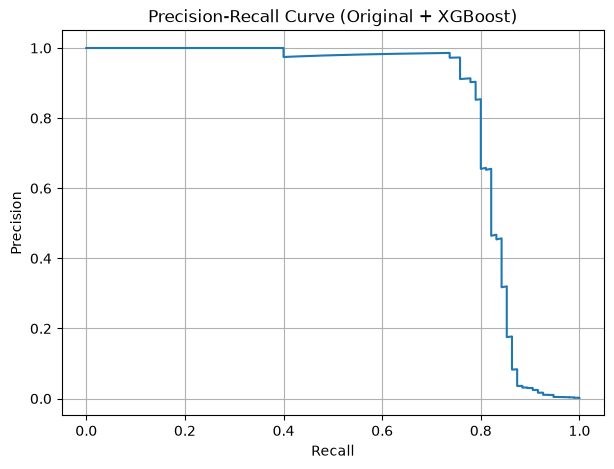

In [58]:
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.figure(figsize=(7, 5))
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Original + XGBoost)")
plt.grid(True)
save_plot("05_pr_curve.png")
plt.show()

Graph saved: outputs\graphs\06_threshold_curve.png


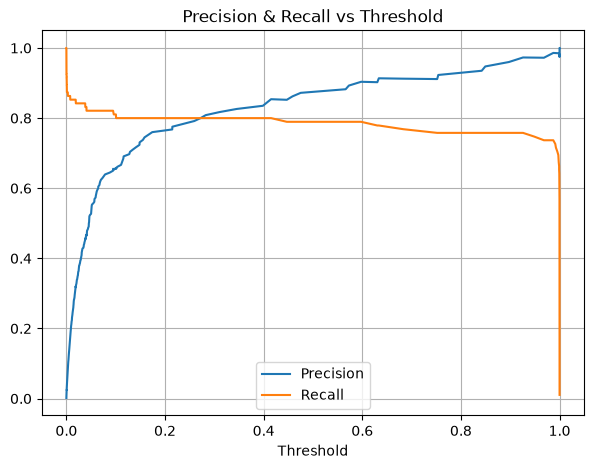

In [59]:
plt.figure(figsize=(7, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold")
plt.legend()
plt.title("Precision & Recall vs Threshold")
plt.grid(True)
save_plot("06_threshold_curve.png")
plt.show()

- Precision stays between 0.9 and 1.0 until recall is about 0.80. Beyond that point precision collapses, so trying to catch more than about 80% of fraud with this model creates a large number of false alarms.
- Between thresholds 0.1 and 0.6, recall stays near 0.80 while precision rises from about 0.65 to 0.90. Raising the threshold in this range improves precision at almost no cost in recall.
- Below 0.1, precision falls quickly for a very small recall gain. Above 0.9, recall starts to fall.
- The curves are step-shaped because the test set has only about 95 fraud cases, so a threshold should be reported as a range rather than a single exact value.

### Business cost analysis
Each threshold is scored with a simple cost model:

`Total cost = (false positives x cost of a false alarm) + (false negatives x cost of a missed fraud)`

The two costs below are **assumptions** for illustration. In a real bank they would come from actual fraud losses and review / customer-support costs.

In [60]:
COST_FN = 500
COST_FP = 10

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "FP": fp, "FN": fn,
        "Total Cost": fp * COST_FP + fn * COST_FN,
    })

thr_df = pd.DataFrame(rows).round(4)
print(thr_df.to_string(index=False))
print("\nBest threshold (min cost):")
print(thr_df.loc[thr_df["Total Cost"].idxmin()])

thr_df.to_csv(os.path.join(OUTPUT_DIR, "threshold_analysis.csv"), index=False)

 Threshold  Precision  Recall  FP  FN  Total Cost
      0.05     0.5270  0.8211  70  17        9200
      0.10     0.6581  0.8105  40  18        9400
      0.15     0.7379  0.8000  27  19        9770
      0.20     0.7677  0.8000  23  19        9730
      0.25     0.7917  0.8000  20  19        9700
      0.30     0.8172  0.8000  17  19        9670
      0.35     0.8352  0.8000  15  19        9650
      0.40     0.8444  0.8000  14  19        9640
      0.45     0.8621  0.7895  12  20       10120
      0.50     0.8824  0.7895  10  20       10100
      0.55     0.8824  0.7895  10  20       10100
      0.60     0.9024  0.7789   8  21       10580
      0.65     0.9125  0.7684   7  22       11070
      0.70     0.9114  0.7579   7  23       11570
      0.75     0.9114  0.7579   7  23       11570
      0.80     0.9351  0.7579   5  23       11550
      0.85     0.9600  0.7579   3  23       11530
      0.90     0.9730  0.7579   2  23       11520
      0.95     0.9722  0.7368   2  25       12520


The lowest cost is at threshold **0.05** (cost 9,200: 70 false alarms, 17 missed fraud). The gap to threshold 0.40 (cost 9,640: 14 false alarms, 19 missed fraud) is only about one missed fraud, which is within the noise of a test set with about 95 fraud cases. Going from 0.40 down to 0.05 catches 2 more fraud but adds 56 extra false alarms.

| Strategy | Threshold | Precision | Recall | FP | FN | When to use |
|---|---|---|---|---|---|---|
| Maximum fraud catch | 0.05 | 0.53 | 0.82 | 70 | 17 | Fraud losses are very large and the review team is big |
| **Balanced (chosen)** | **0.40** | **0.84** | **0.80** | **14** | **19** | Near-minimum cost with 5x fewer false alarms |
| Low customer friction | 0.85 to 0.90 | 0.96 to 0.97 | 0.76 | 2 to 3 | 23 | Customer experience matters most |

The chosen threshold is **0.40**, within a reasonable range of 0.3 to 0.5. If a missed fraud were much more expensive (for example 2000 instead of 500), a lower threshold would be preferred. If a false alarm were more expensive (blocked cards, call-centre work), a higher threshold would be preferred.

**Caveat:** the threshold was chosen on the test set, so the numbers are slightly optimistic. In production the threshold should be chosen on a separate validation set, and the test set should be kept for the final check only.

## 8. Final model evaluation at the chosen threshold

In [61]:
THRESHOLD = 0.40

pred_final = (proba >= THRESHOLD).astype(int)

print(f"Threshold : {THRESHOLD}")
print(f"Precision : {precision_score(y_test, pred_final):.4f}")
print(f"Recall    : {recall_score(y_test, pred_final):.4f}")
print(f"F1        : {f1_score(y_test, pred_final):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, proba):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, proba):.4f}")

Threshold : 0.4
Precision : 0.8444
Recall    : 0.8000
F1        : 0.8216
ROC-AUC   : 0.9692
PR-AUC    : 0.8204


Graph saved: outputs\graphs\07_confusion_matrix.png


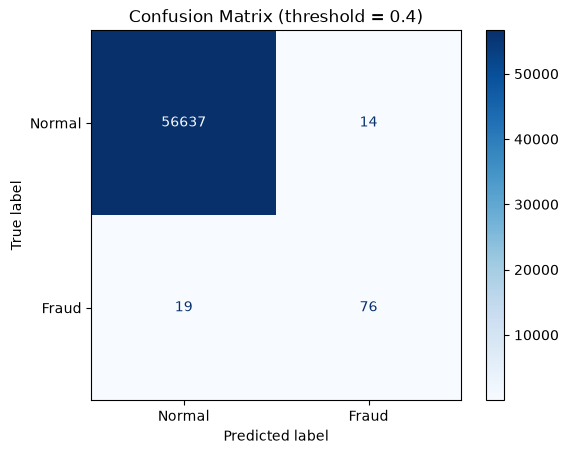

In [62]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final,
    display_labels=["Normal", "Fraud"],
    cmap="Blues", values_format="d",
)
plt.title(f"Confusion Matrix (threshold = {THRESHOLD})")
save_plot("07_confusion_matrix.png")
plt.show()

The confusion matrix shows the four outcomes at threshold 0.40:
- **True positives:** fraud correctly caught.
- **False negatives:** fraud that was missed (the most costly error).
- **False positives:** legitimate transactions flagged by mistake (customer friction).
- **True negatives:** legitimate transactions correctly passed.

### Feature importance

V14    0.5247
V4     0.0605
V8     0.0380
V12    0.0340
V10    0.0289
V3     0.0274
V13    0.0219
V19    0.0213
V17    0.0179
V11    0.0167
dtype: float32
Graph saved: outputs\graphs\08_feature_importance.png


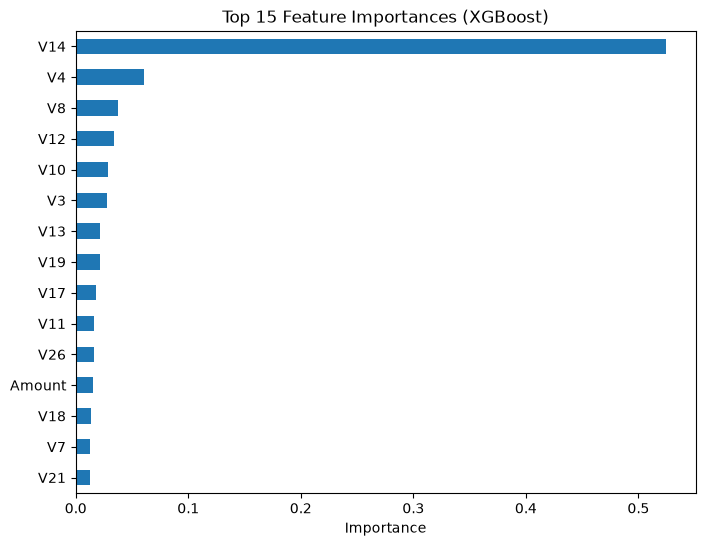

In [63]:
importances = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10).round(4))

plt.figure(figsize=(8, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Feature Importances (XGBoost)")
plt.xlabel("Importance")
save_plot("08_feature_importance.png")
plt.show()

The plot shows which features the model relies on most. Comparing it with the earlier correlation plot shows whether the model uses the same features or also non-linear patterns that simple correlation cannot capture.

## 9. Predicting a single transaction
`predict_fraud` takes one transaction with **raw** (unscaled) values, scales `Time` and `Amount` with the fitted scaler, and returns the label and fraud probability using the chosen threshold.

`V1` to `V28` are anonymized PCA features, so a real user cannot type them in. For the demo, rows from the original data are used.

In [64]:
def predict_fraud(transaction, model=final_model, scaler_obj=scaler, threshold=THRESHOLD, columns=X.columns):
    row = pd.DataFrame([transaction])[list(columns)].copy()
    row[["Time", "Amount"]] = scaler_obj.transform(row[["Time", "Amount"]])
    prob = model.predict_proba(row)[0, 1]
    label = "FRAUD" if prob >= threshold else "NOT FRAUD"
    return label, round(float(prob), 4)

In [65]:
fraud_idx = y_test[y_test == 1].index[0]
normal_idx = y_test[y_test == 0].index[0]

for idx in [fraud_idx, normal_idx]:
    raw = data_frame.loc[idx, X.columns].to_dict()
    label, prob = predict_fraud(raw)
    print(f"Actual: {data_frame.loc[idx, 'Class']} | Predicted: {label} | Probability: {prob}")

Actual: 1 | Predicted: FRAUD | Probability: 0.9975
Actual: 0 | Predicted: NOT FRAUD | Probability: 0.0


## 10. Saving the model and results
- `outputs/models/` : XGBoost model, scaler, a Random Forest for reference, and `config.json` (threshold and feature order).
- `outputs/graphs/` : all plots saved above (`01` to `08`).
- `outputs/` : `model_comparison.csv` and `threshold_analysis.csv`.

In [66]:
save_artifacts(
    model=final_model,
    scaler=scaler,
    threshold=THRESHOLD,
    feature_columns=X.columns,
    extra_models={"random_forest_smote": trained_models[("SMOTE", "RandomForest")]},
)

Models saved in: outputs\models


### Check: load the saved files and predict again
This confirms the saved model, scaler and config work on their own, without the training objects in memory. The result should match the previous demo.

In [67]:
loaded_model = joblib.load(os.path.join(MODELS_DIR, "xgboost_fraud_model.pkl"))
loaded_scaler = joblib.load(os.path.join(MODELS_DIR, "scaler.pkl"))
with open(os.path.join(MODELS_DIR, "config.json")) as f:
    config = json.load(f)

for idx in [fraud_idx, normal_idx]:
    raw = data_frame.loc[idx, X.columns].to_dict()
    label, prob = predict_fraud(
        raw, model=loaded_model, scaler_obj=loaded_scaler,
        threshold=config["threshold"], columns=config["feature_columns"],
    )
    print(f"Actual: {data_frame.loc[idx, 'Class']} | Predicted: {label} | Probability: {prob}")

Actual: 1 | Predicted: FRAUD | Probability: 0.9975
Actual: 0 | Predicted: NOT FRAUD | Probability: 0.0


## 11. Conclusion

**Problem.** Fraud is only 0.17% of transactions, so accuracy is meaningless and the models are judged on precision, recall and PR-AUC.

**What worked.** XGBoost trained on the original data with `scale_pos_weight` gave the best PR-AUC (0.820) with balanced precision (0.88) and recall (0.79) at the default threshold. SMOTE and SMOTE + undersampling did not improve results on this dataset: they raised recall slightly for XGBoost but cut precision a lot, causing many more false alarms.

**Precision vs recall.** Lowering the threshold catches more fraud but flags more legitimate customers. At threshold 0.05 the model catches 82% of fraud with 53% precision, while at 0.40 it catches 80% with 84% precision. The extra fraud caught at very low thresholds costs many more false alarms.

**Business decision.** A threshold of about 0.40 (range 0.3 to 0.5) is recommended: near-minimum cost under the assumed costs, with about 5 times fewer false alarms than the lowest-cost threshold. The right value depends on the bank's real cost of a missed fraud versus a false alarm.

**Limitations**
- The test set has only about 95 fraud cases, so small metric differences between models and thresholds are not reliable.
- The cost values (500 and 10) are assumptions.
- The threshold was selected on the test set; a separate validation set should be used in production.
- The data covers only two days of transactions, and fraud patterns change over time, so the model would need regular retraining and monitoring.